# Setup the project

## Importing all the needed libraries

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Loading the data

In [16]:
flights_data = pd.read_csv('../../data/Clean_Dataset.csv')
flights_data.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [17]:
# Remove the first column
flights_data = flights_data.drop(columns='Unnamed: 0')

The flight column is redundant. It has unique flight codes which does not help in any way to the prediction of the price. There is a separate column for airline as well so we can drop the 'flight' one.

In [18]:
flights_data = flights_data.drop(columns='flight')

In [19]:
# Check for missing values in the dataset
print(flights_data.isnull().any())

airline             False
source_city         False
departure_time      False
stops               False
arrival_time        False
destination_city    False
class               False
duration            False
days_left           False
price               False
dtype: bool


It looks like the dataset is clean and there are no missing values in any column.

In [20]:
# Information about the dataset
flights_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  str    
 1   source_city       300153 non-null  str    
 2   departure_time    300153 non-null  str    
 3   stops             300153 non-null  str    
 4   arrival_time      300153 non-null  str    
 5   destination_city  300153 non-null  str    
 6   class             300153 non-null  str    
 7   duration          300153 non-null  float64
 8   days_left         300153 non-null  int64  
 9   price             300153 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 22.9 MB


In [21]:
# Statistical description of numerical data
flights_data.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


# Exploring the data

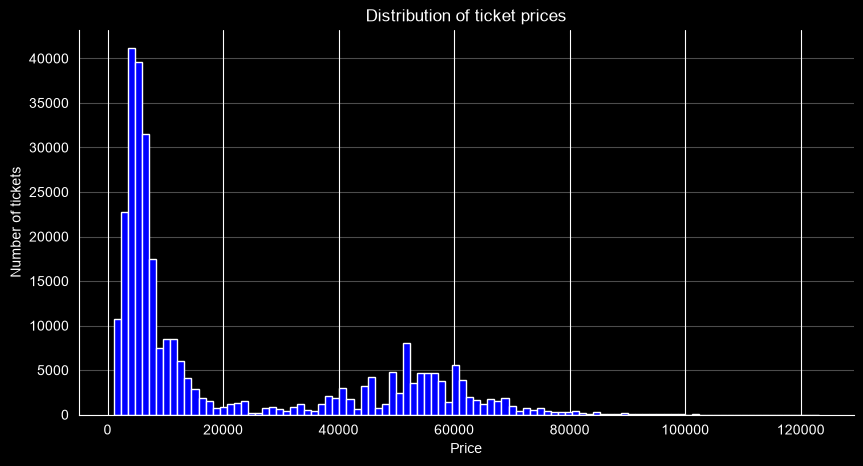

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(flights_data['price'], bins=100, color='blue')
ax.set_title('Distribution of ticket prices')
ax.set_xlabel('Price')
ax.set_ylabel('Number of tickets')
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

In [23]:
# Setup a list for the price classes
classes = list(flights_data['class'].unique())
print(classes)

['Economy', 'Business']


In [24]:
median_price_per_class = flights_data.groupby('class')['price'].median()
mean_price_per_class = flights_data.groupby('class')['price'].mean()

for cls in classes:
    print(f"{cls}:\n"
          f"- Median price: {median_price_per_class[cls]:.2f}\n"
          f"- Mean price: {mean_price_per_class[cls]:.2f}")

Economy:
- Median price: 5772.00
- Mean price: 6572.34
Business:
- Median price: 53164.00
- Mean price: 52540.08


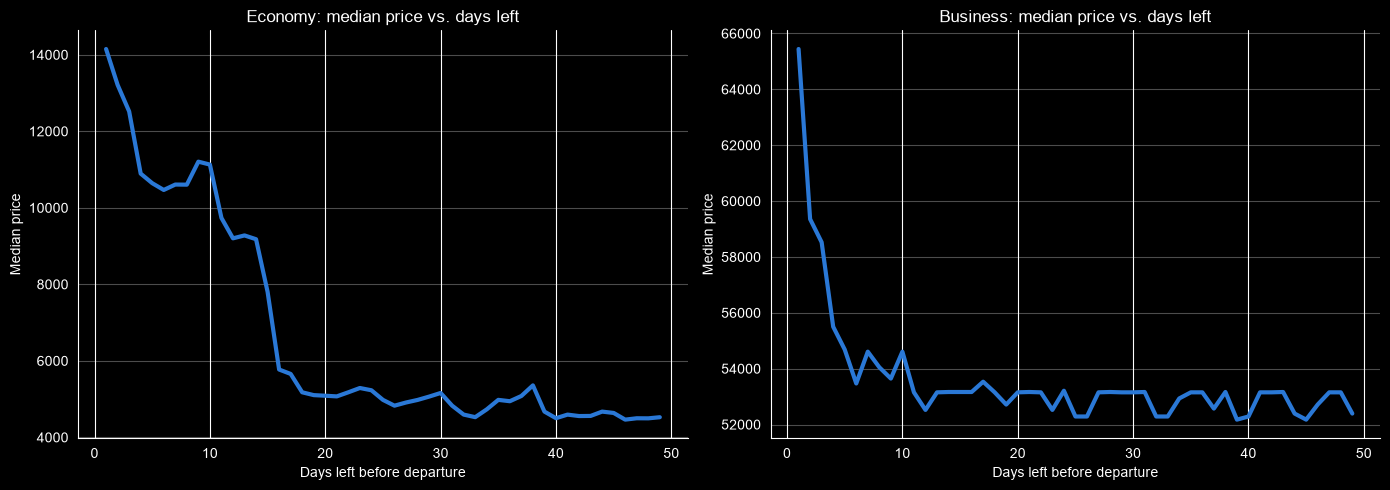

In [25]:
median_price = flights_data.groupby(['class', 'days_left'])['price'].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls in zip(axes, classes):
    ax.plot(median_price[cls].index, median_price[cls].values, color='#2a78d6', linewidth=3)
    ax.set_title(f'{cls}: median price vs. days left')
    ax.set_xlabel('Days left before departure')
    ax.set_ylabel('Median price')
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

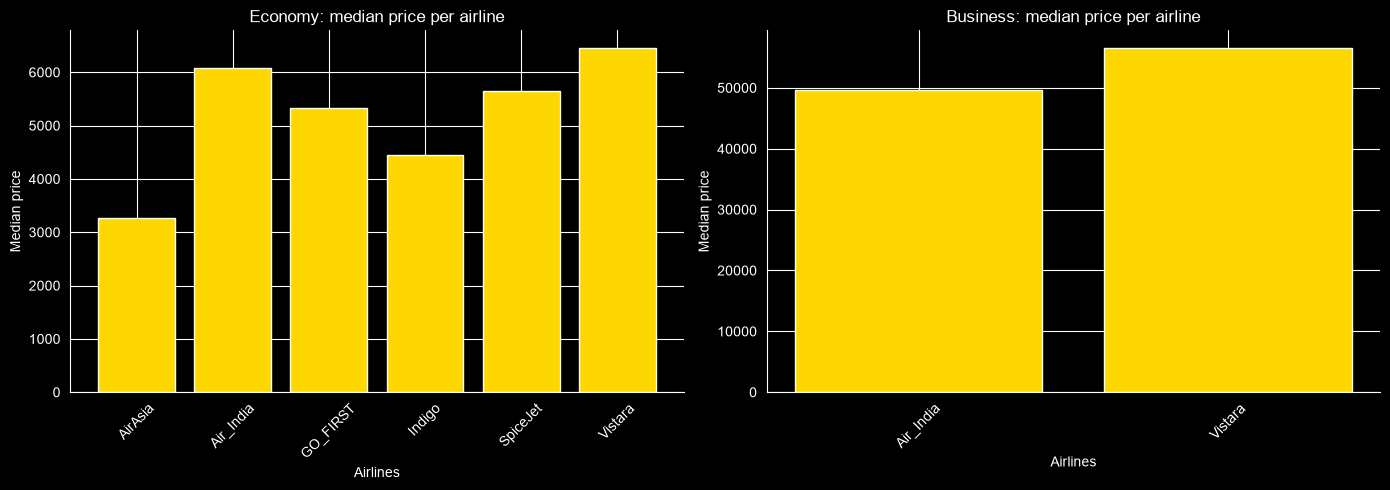

In [26]:
median_price = flights_data.groupby(['class', 'airline'])['price'].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls in zip(axes, classes):
    data = median_price[cls]
    ax.bar(data.index, data.values, color='gold')
    ax.set_title(f"{cls}: median price per airline")
    ax.set_xlabel("Airlines")
    ax.set_ylabel('Median price')
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Routes

Median price for every source → destination pair, split by class. Each cell also shows the number of tickets (n) on that route. The diagonal is empty because no route starts and ends in the same city. Each class has its own colour scale, so compare colours within one panel, not across the two.

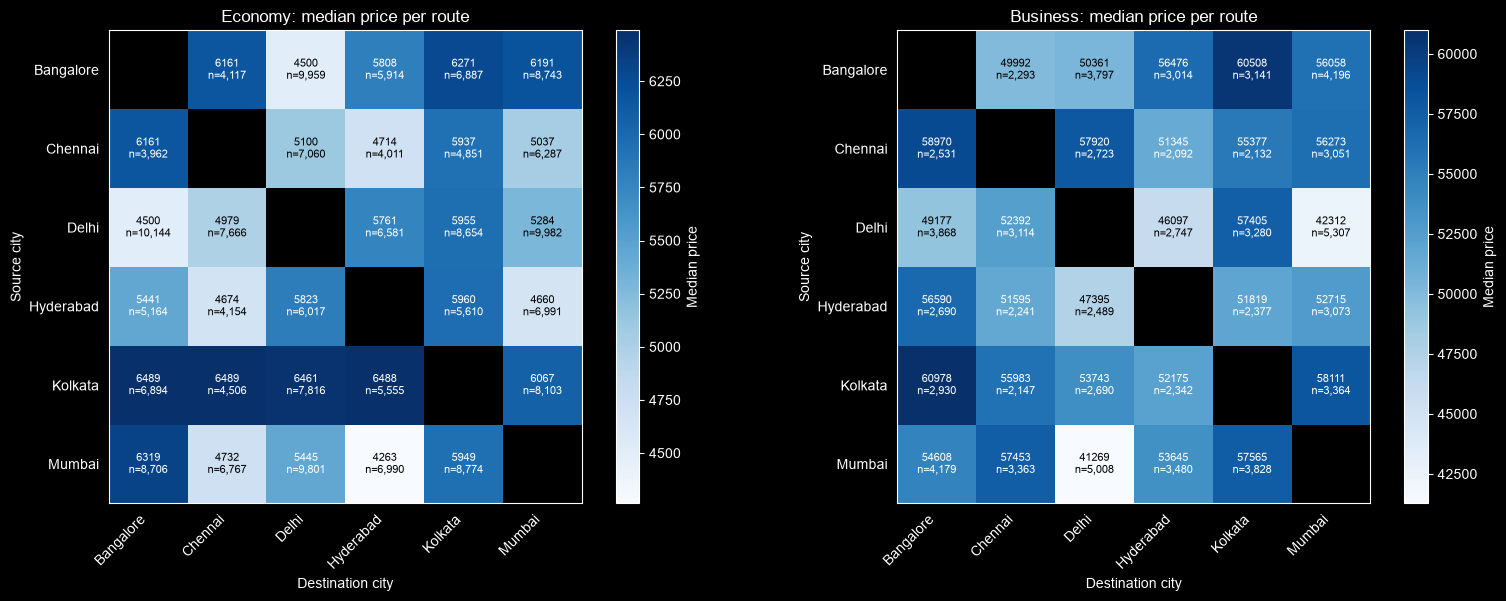

In [32]:
cities = sorted(flights_data['source_city'].unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cls in zip(axes, classes):
    subset = flights_data[flights_data['class'] == cls]
    routes = subset.groupby(['source_city', 'destination_city'])['price']
    median = routes.median().unstack().reindex(index=cities, columns=cities)
    count = routes.size().unstack().reindex(index=cities, columns=cities)

    im = ax.imshow(median.values, cmap='Blues')
    ax.set_xticks(range(len(cities)), cities, rotation=45, ha='right')
    ax.set_yticks(range(len(cities)), cities)
    ax.set_xlabel('Destination city')
    ax.set_ylabel('Source city')
    ax.set_title(f'{cls}: median price per route')
    ax.grid(axis='x', alpha=0)
    ax.grid(axis='y', alpha=0)

    midpoint = (np.nanmin(median.values) + np.nanmax(median.values)) / 2
    for i in range(len(cities)):
        for j in range(len(cities)):
            value = median.iat[i, j]
            if pd.isna(value):
                continue
            ax.text(j, i, f'{value:.0f}\nn={count.iat[i, j]:,.0f}',
                    ha='center', va='center', fontsize=8,
                    color='white' if value > midpoint else 'black')

    fig.colorbar(im, ax=ax, label='Median price')
plt.tight_layout()
plt.show()